<a href="https://colab.research.google.com/github/manjari-varma05/EmotionPulse/blob/main/LLM_AAT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Emotion classification with RNNs,LSTMs,and GRUs:
Classifying the text into 6 emotions(sadness,joy,love,anger,fear,surprise) by comparing plain recurrent models before building an Advanced bidirectional GRU

1.Import libraries:
tensorflow/keras,HuggingFace Datasets,and evaluation tools


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
#to ease the process of loading dataset
from datasets import load_dataset


2.Load Dataset:
Load the dair-ai/emotion dataset from HuggingFace

In [3]:
emotion_dataset=load_dataset("dair-ai/emotion")
train_text=emotion_dataset["train"]["text"]
train_labels=emotion_dataset["train"]["label"]
test_text=emotion_dataset["test"]["text"]
test_labels=emotion_dataset["test"]["label"]

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [4]:
label_names=emotion_dataset['train'].features['label'].names
print(label_names)

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


In [5]:
#creating a dataframe
df_train=pd.DataFrame({'text':train_text,
                       'label':[label_names[i] for i in train_labels]})
df_test=pd.DataFrame({'text':test_text,
                      'label':[label_names[i] for i in test_labels]})


In [6]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [7]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [8]:
df_train.isnull().sum()

,0
text,0
label,0


Exploratory Data Analysis:
Visualise class distribution across 6 emotion labels

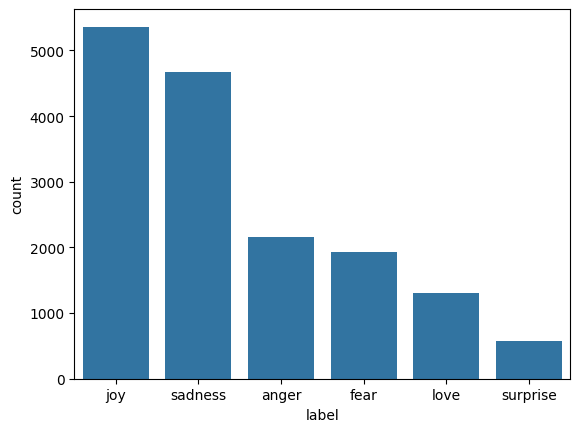

In [9]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)
plt.show()

Data Preprocessing -Using NLP:
tokenize text,pad sequences to max length 50,and convert labels to numpy array

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words=10000
tokenizer=Tokenizer(num_words=max_words,oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence=tokenizer.texts_to_sequences(df_train['text'])
test_sequence=tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence=pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence=pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

train_labels=np.array(train_labels)
test_labels=np.array(test_labels)

num_classes=len(np.unique(train_labels))

print("Vocabulary size:",len(tokenizer.word_index))
print("Number of classes:",num_classes)
print("Max length of each input sentence:",padded_train_sequence.shape[1])


Vocabulary size: 15213
Number of classes: 6
Max length of each input sentence: 50


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    padded_train_sequence,
    train_labels,
    test_size=0.2,
    random_state=42,
    stratify=train_labels
)

Shared training utilities:
Compute balanced class weigths to handle dataset skew and setup early stopping

In [12]:
from sklearn.utils import class_weight
import numpy as np

classes = np.unique(y_train)

class_wts = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_wt_dict = dict(zip(classes, class_wts))

In [13]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

Plain foundational models:
train plain(non bidirectional) simple RNNs,stand LSTMs and stand GRUs

In [32]:
#Model 1:Simple RNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Embedding,Dense,Dropout,LSTM,GRU
mod = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

mod.build(input_shape=(None, 50))
rnn_mod=mod.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
mod.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 50, 128)        │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 50, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,325,638 (5.06 MB)

 Trainable params: 1,325,638 (5.06 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
mod.fit(padded_train_sequence,
            train_labels,
            validation_data=(padded_test_sequence,test_labels),epochs=20,batch_size=32,validation_split=0.2,class_weight=class_wt_dict,callbacks=[early_stop])
rnn_loss,rnn_acc=mod.evaluate(padded_test_sequence,test_labels)
print("RNN Loss:",rnn_loss)
print("RNN Accuracy:",rnn_acc)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.1652 - loss: 1.8989 - val_accuracy: 0.2485 - val_loss: 1.7730
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1570 - loss: 1.8035 - val_accuracy: 0.1980 - val_loss: 1.7876
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1638 - loss: 1.7871 - val_accuracy: 0.0915 - val_loss: 1.8354
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2485 - loss: 1.7730
RNN Loss: 1.7729692459106445
RNN Accuracy: 0.2485000044107437


In [34]:
#Satndard LSTM
lstm_mod = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])
lstm_mod.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history_lstm = lstm_mod.fit(
    X_train,
    y_train,
    validation_data=(padded_test_sequence, test_labels),
    epochs=20,
    batch_size=32,
    callbacks=[early_stop]
)

lstm_loss, lstm_accuracy = lstm_mod.evaluate(
    padded_test_sequence,
    test_labels
)

print("Test loss:", lstm_loss)
print("Test accuracy:", lstm_accuracy)

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.3180 - loss: 1.6024 - val_accuracy: 0.3475 - val_loss: 1.5670
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3266 - loss: 1.5853 - val_accuracy: 0.2905 - val_loss: 1.5674
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.3250 - loss: 1.5813 - val_accuracy: 0.3480 - val_loss: 1.5618
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3475 - loss: 1.5670
Test loss: 1.5669916868209839
Test accuracy: 0.3474999964237213


In [35]:
#Standard GRU
gru_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128,input_length=50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


history_gru = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_wt_dict,
    callbacks=[early_stop]
)

gru_loss, gru_accuracy = gru_model.evaluate(
    padded_test_sequence,
    test_labels
)

print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


400/400 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1583 - loss: 1.7960 - val_accuracy: 0.1216 - val_loss: 1.7954
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.1570 - loss: 1.7954 - val_accuracy: 0.2887 - val_loss: 1.7805
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.1630 - loss: 1.7955 - val_accuracy: 0.1191 - val_loss: 1.8007
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.1120 - loss: 1.7966
GRU Loss: 1.796644926071167
GRU Accuracy: 0.1120000034570694


Ranking and Selection:
Rank foundational models to pick the best base cell for the next phase

In [36]:
res_df=pd.DataFrame(
    {
        'Model':['RNN','LSTM','GRU'],
        'Loss':[rnn_loss,lstm_loss,gru_loss],
        'Accuracy':[rnn_acc,lstm_accuracy,gru_accuracy]
    }
).sort_values(by='Accuracy',ascending=False)
res_df
res_df

,Model,Loss,Accuracy
1,LSTM,1.566992,0.3475
0,RNN,1.772969,0.2485
2,GRU,1.796645,0.1120


In [1]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


Advanced bidirectional GRU:
Enhance GRU with bidirectional layers,300D embeddings and 0.5 dropout regularisation

In [37]:
from tensorflow.keras.layers import Bidirectional
BiGRU=Sequential([
    Embedding(input_dim=max_words, output_dim=300),
    Bidirectional(GRU(units=128,return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')]
)
BiGRU.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
BiGRU.build(input_shape=(None, 50))
BiGRU.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 50, 300)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 50, 256)        │       330,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,454,662 (13.18 MB)

 Trainable params: 3,454,662 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
BiGRU.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_wt_dict,
    callbacks=[early_stop]
)
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(
    padded_test_sequence,
    test_labels
)
print("BiGRU loss:",BiGRU_loss)
print("BiGRU accuracy:",BiGRU_accuracy)

Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 71s 170ms/step - accuracy: 0.4988 - loss: 1.1717 - val_accuracy: 0.8678 - val_loss: 0.5026
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 68s 171ms/step - accuracy: 0.8970 - loss: 0.3152 - val_accuracy: 0.9091 - val_loss: 0.2756
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 84s 176ms/step - accuracy: 0.9389 - loss: 0.1694 - val_accuracy: 0.9153 - val_loss: 0.2675
Epoch 4/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 80s 171ms/step - accuracy: 0.9562 - loss: 0.1208 - val_accuracy: 0.9184 - val_loss: 0.2858
Epoch 5/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 69s 172ms/step - accuracy: 0.9669 - loss: 0.0926 - val_accuracy: 0.9225 - val_loss: 0.2587
Epoch 6/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 69s 171ms/step - accuracy: 0.9718 - loss: 0.0789 - val_accuracy: 0.9191 - val_loss: 0.2764
Epoch 7/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 84s 177ms/step - accuracy: 0.9783 - loss: 0.0623 - val_accuracy: 0.9241 - val_loss: 0.2788
Epoch 8/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 68s 169ms/step - accuracy: 0.9851 - loss: 0

In [19]:

import numpy as np
import optuna
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Bidirectional, Dropout, Dense
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

# Number of classes and vocabulary size
num_classes = 6
max_words = 10000




def objective(trial):

    # Hyperparameters to tune
    embedding_dim = trial.suggest_categorical(
        "embedding_dim", [100, 200, 300]
    )

    gru_units_1 = trial.suggest_categorical(
        "gru_units_1", [64, 128, 256]
    )

    gru_units_2 = trial.suggest_categorical(
        "gru_units_2", [32, 64, 128]
    )

    dropout_rate = trial.suggest_float(
        "dropout_rate", 0.2, 0.6, step=0.1
    )

    learning_rate = trial.suggest_float(
        "learning_rate", 1e-4, 1e-2, log=True
    )

    batch_size = trial.suggest_categorical(
        "batch_size", [32, 64, 128]
    )

    optimizer_name = trial.suggest_categorical(
        "optimizer", ["adam", "rmsprop"]
    )

    # Build BiGRU model
    model = Sequential([
        Embedding(
            input_dim=max_words,
            output_dim=embedding_dim,
            mask_zero=True
        ),
        Bidirectional(
            GRU(gru_units_1, return_sequences=True)
        ),
        Dropout(dropout_rate),
        Bidirectional(
            GRU(gru_units_2)
        ),
        Dropout(dropout_rate),
        Dense(num_classes, activation="softmax")
    ])

    # Select optimizer
    if optimizer_name == "adam":
        optimizer = Adam(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )



    # Train the trial model
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )

    # Best validation accuracy
    best_val_accuracy = max(history.history["val_accuracy"])

    tf.keras.backend.clear_session()

    return best_val_accuracy


# Run Optuna optimization
study = optuna.create_study(
    direction="maximize",
    study_name="EmotionPulse_BiGRU_Tuning"
)

study.optimize(objective, n_trials=20)

print("Best Validation Accuracy:", study.best_value)
print("Best Hyperparameters:")
print(study.best_params)




[I 2026-10-27 09:14:46,749] A new study created in memory with name: EmotionPulse_BiGRU_Tuning
[I 2026-10-27 09:14:57,571] Trial 0 finished with value: 0.41593751311302185 and parameters: {'embedding_dim': 200, 'gru_units_1': 128, 'gru_units_2': 64, 'dropout_rate': 0.4, 'learning_rate': 0.00020418285911363526, 'batch_size': 128, 'optimizer': 'rmsprop'}. Best is trial 0 with value: 0.41593751311302185.
[I 2026-10-27 09:15:22,369] Trial 1 finished with value: 0.9318749904632568 and parameters: {'embedding_dim': 300, 'gru_units_1': 128, 'gru_units_2': 64, 'dropout_rate': 0.30000000000000004, 'learning_rate': 0.0013577629118649674, 'batch_size': 32, 'optimizer': 'adam'}. Best is trial 1 with value: 0.9318749904632568.
[I 2026-10-27 09:15:46,354] Trial 2 finished with value: 0.9009374976158142 and parameters: {'embedding_dim': 200, 'gru_units_1': 128, 'gru_units_2': 32, 'dropout_rate': 0.6, 'learning_rate': 0.0004362944986772285, 'batch_size': 32, 'optimizer': 'adam'}. Best is trial 1 with 

Best Validation Accuracy: 0.9356250166893005
Best Hyperparameters:
{'embedding_dim': 300, 'gru_units_1': 128, 'gru_units_2': 32, 'dropout_rate': 0.4, 'learning_rate': 0.009224729587954028, 'batch_size': 64, 'optimizer': 'rmsprop'}


In [20]:

# Build the final BiGRU model using the best hyperparameters

final_model = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=300,
        mask_zero=True
    ),
    Bidirectional(
        GRU(128, return_sequences=True)
    ),
    Dropout(0.4),
    Bidirectional(
        GRU(32)
    ),
    Dropout(0.4),
    Dense(6, activation="softmax")
])

# Compile the model
final_model.compile(
    optimizer=RMSprop(learning_rate=0.009224729587954028),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Early stopping
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the final tuned BiGRU
history = final_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

# Evaluate on the test set
BiGRU_loss, BiGRU_accuracy = final_model.evaluate(
    padded_test_sequence,
    test_labels,
    verbose=1
)

print("Tuned BiGRU loss:", BiGRU_loss)
print("Tuned BiGRU accuracy:", BiGRU_accuracy)
print(f"Tuned BiGRU accuracy: {BiGRU_accuracy * 100:.2f}%")


Epoch 1/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.6622 - loss: 0.9072 - val_accuracy: 0.8966 - val_loss: 0.2741
Epoch 2/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9266 - loss: 0.2009 - val_accuracy: 0.9303 - val_loss: 0.1636
Epoch 3/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9416 - loss: 0.1445 - val_accuracy: 0.9287 - val_loss: 0.2444
Epoch 4/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9553 - loss: 0.1185 - val_accuracy: 0.9381 - val_loss: 0.1555
Epoch 5/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9612 - loss: 0.1014 - val_accuracy: 0.9344 - val_loss: 0.2027
Epoch 6/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9680 - loss: 0.0853 - val_accuracy: 0.9294 - val_loss: 0.2162
Epoch 7/15
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9739 - loss: 0.0681 - val_accuracy: 0.9306 - val_loss: 0.2197
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9305 - loss: 0.1530
Tuned BiGRU loss: 0.1529

In [22]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dropout, Dense

BiLSTM = Sequential([
    Embedding(input_dim=max_words, output_dim=300),
    Bidirectional(LSTM(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(LSTM(units=64)),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

BiLSTM.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

BiLSTM.build(input_shape=(None, 50))
BiLSTM.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 300)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 50, 256)        │       439,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,604,422 (13.75 MB)

 Trainable params: 3,604,422 (13.75 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:

history_bilstm = BiLSTM.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_wt_dict,
    callbacks=[early_stop]
)


Epoch 1/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.5145 - loss: 1.1960 - val_accuracy: 0.8650 - val_loss: 0.4364
Epoch 2/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9021 - loss: 0.3139 - val_accuracy: 0.9087 - val_loss: 0.2786
Epoch 3/20
400/400 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.9327 - loss: 0.1942 - val_accuracy: 0.9072 - val_loss: 0.2832


In [24]:

bilstm_loss, bilstm_accuracy = BiLSTM.evaluate(
    padded_test_sequence,
    test_labels
)

print(f"BiLSTM Test Loss: {bilstm_loss:.4f}")
print(f"BiLSTM Test Accuracy: {bilstm_accuracy:.4f}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8585 - loss: 0.4675
BiLSTM Test Loss: 0.4675
BiLSTM Test Accuracy: 0.8585


Comparing bidirectional LSTM and bidirectional GRU

In [25]:

res_df = pd.DataFrame({
    'Model': ['BiGRU', 'BiLSTM'],
    'Loss': [

        BiGRU_loss,
        bilstm_loss
    ],
    'Accuracy': [

        BiGRU_accuracy,
        bilstm_accuracy
    ]
}).sort_values(by='Accuracy', ascending=False).reset_index(drop=True)

res_df


,Model,Loss,Accuracy
0,BiGRU,0.152979,0.9305
1,BiLSTM,0.467493,0.8585


Overall Evaluation and Bias Analysis:
Consolidate test metrics,plot raw and normalised confusion matrices and analyse the bias

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step


<Axes: >

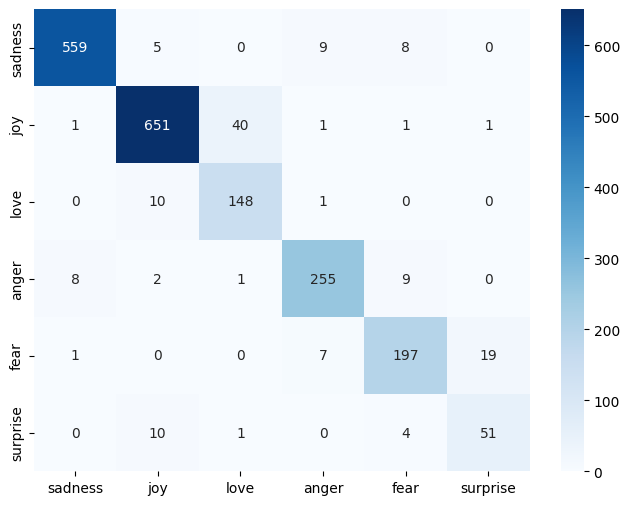

In [27]:
from sklearn.metrics import confusion_matrix
BiGRU_pred=np.argmax(final_model.predict(padded_test_sequence),axis=1)

conf_mat=confusion_matrix(test_labels,BiGRU_pred)
plt.figure(figsize=(8,6))
sns.heatmap(conf_mat,annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)


In [28]:
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Get predictions on the test dataset
y_prob = final_model.predict(padded_test_sequence, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.asarray(test_labels)

# 1. Precision
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# 2. Recall
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# 3. F1-score
f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# 4. ROC-AUC (multiclass)
roc_auc = roc_auc_score(
    y_true, y_prob, multi_class="ovr", average="weighted"
)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Precision: 0.9339
Recall:    0.9305
F1-score:  0.9315
ROC-AUC:   0.9974


Final Predictions:
Test the winning model on unseen sentences

In [29]:
from random import sample

sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]
sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')
sample_predictions = np.argmax(final_model.predict(sample_padded),axis=1)

for i in range(len(sample_texts)):
    print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


Save the final model and tokenizer:
Export trained model and tokenzier artifacts for API development

In [31]:
import os
import pickle

model_dir='Artifacts'
os.makedirs(model_dir,exist_ok=True)
#Save the bigru mod
final_model.save(os.path.join(model_dir,'final_model.keras'))
#Save the tokenizer
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as f:
    pickle.dump(tokenizer,f)